# 02. Results and comparisons

This notebook rebuilds the project's results from the out-of-fold predictions saved in `artifacts/preds/`. No images and no training are needed.

**What you will see**

1. A leakage check on the cross-validation folds.
2. A results table for all seven arms (AUROC, AUPRC, ECE as mean and standard deviation over folds).
3. ROC curves for three representative arms.
4. Paired bootstrap confidence intervals on the difference between arms. This is the project's actual result, because a table of per-arm scores cannot say whether one arm really beat another when both are scored on the same samples.

The bootstrap step takes about a minute.

## Setup

As in notebook 01, `import src` must come first (see `src/__init__.py`).

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", message="IProgress not found")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "notebooks")]

import src  # noqa: F401  Keep this first: it sets OMP_NUM_THREADS and loads LightGBM before PyTorch.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.metrics import roc_auc_score

import viz

FIG_DIR = ROOT / "docs" / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

## 1. Check the folds

Every arm must use the same folds, and no patient group may appear in more than one fold. The project stores its folds in `artifacts/folds/` and provides `check_no_group_leak`, which raises an error if any group spans two folds. The group key is `{parent_id}_{class}`, because `001_h` and `001_a` are different patients who share a number.

In [2]:
from src.splits import check_no_group_leak, fold_summary, load_folds

folds = load_folds()
check_no_group_leak(folds)  # raises AssertionError on a leak
print("No group spans more than one fold.\n")
fold_summary(folds)

No group spans more than one fold.



,n,n_groups,pos_rate
fold,,,
0,200,200,0.5
1,200,200,0.5
2,200,200,0.5
3,200,200,0.5
4,200,200,0.5


## 2. Results table

We load the saved out-of-fold predictions and score each fold separately, using the project's own metric functions (`src.metrics`). ECE is expected calibration error, where lower is better.

The `group` column separates arms that use only CBC values from arms that use the smear image. **Every image arm inherits an acquisition artifact** (README, trap 4): even empty slide background predicts the diagnosis, so image scores cannot be read as a pure morphology result.

In [3]:
from src.metrics import bootstrap_delta, summarize

ARMS = {
    "concat_stainnorm": ("Concat fusion (stain-norm)", "image"),
    "film_stainnorm": ("FiLM fusion (stain-norm)", "image"),
    "image": ("Image, raw", "image"),
    "image_stainnorm": ("Image, stain-norm", "image"),
    "lgbm": ("LightGBM (CBC)", "cbc"),
    "mlp": ("MLP (CBC)", "cbc"),
    "lgbm_withhb": ("LightGBM + HGB/HCT", "cbc"),
}
preds = {k: pd.read_csv(ROOT / "artifacts" / "preds" / f"{k}.csv") for k in ARMS}

rows = []
for key, (label, group) in ARMS.items():
    per_fold = pd.DataFrame(
        [summarize(g["y"].to_numpy(), g["pred"].to_numpy()) for _, g in preds[key].groupby("fold")]
    )
    rows.append(
        {
            "arm": key,
            "label": label,
            "group": group,
            **{f"{m}_mean": per_fold[m].mean() for m in per_fold},
            **{f"{m}_std": per_fold[m].std(ddof=0) for m in per_fold},
        }
    )
summary = pd.DataFrame(rows).sort_values("auroc_mean", ascending=False).reset_index(drop=True)

table = summary[["label", "group"]].copy()
for m in ("auroc", "auprc", "ece"):
    table[m.upper()] = summary.apply(lambda r: f"{r[m + '_mean']:.3f} +/- {r[m + '_std']:.3f}", axis=1)
table

,label,group,AUROC,AUPRC,ECE
0,Concat fusion (stain-norm),image,0.959 +/- 0.015,0.962 +/- 0.013,0.070 +/- 0.018
1,FiLM fusion (stain-norm),image,0.954 +/- 0.016,0.951 +/- 0.022,0.077 +/- 0.018
2,"Image, raw",image,0.948 +/- 0.010,0.946 +/- 0.015,0.095 +/- 0.049
3,"Image, stain-norm",image,0.942 +/- 0.012,0.946 +/- 0.014,0.078 +/- 0.020
4,LightGBM (CBC),cbc,0.690 +/- 0.031,0.636 +/- 0.036,0.097 +/- 0.048
5,MLP (CBC),cbc,0.689 +/- 0.023,0.648 +/- 0.030,0.097 +/- 0.014
6,LightGBM + HGB/HCT,cbc,0.686 +/- 0.025,0.644 +/- 0.034,0.106 +/- 0.023


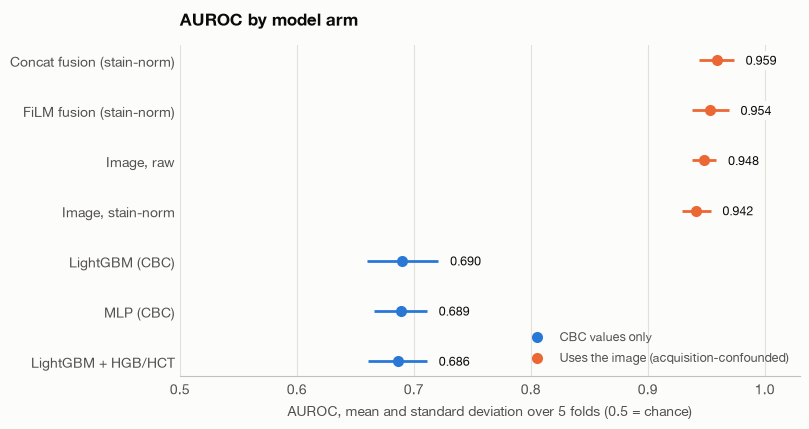

In [4]:
def draw_arms(t):
    fig, ax = viz.new_axes(t, (8, 4.3), grid="x")
    d = summary.iloc[::-1].reset_index(drop=True)  # best arm on top
    colors = {"cbc": t["blue"], "image": t["orange"]}
    for i, r in d.iterrows():
        c = colors[r["group"]]
        ax.errorbar(r["auroc_mean"], i, xerr=r["auroc_std"], fmt="o", color=c, ecolor=c,
                    elinewidth=2, capsize=0, markersize=8, markeredgewidth=0, zorder=3)
        ax.text(r["auroc_mean"] + r["auroc_std"] + 0.01, i, f"{r['auroc_mean']:.3f}",
                va="center", color=t["ink"], fontsize=9,
                bbox=dict(facecolor=t["surface"], edgecolor="none", pad=1.5), zorder=4)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels(d["label"])
    ax.set_xlim(0.5, 1.03)
    ax.set_xlabel("AUROC, mean and standard deviation over 5 folds (0.5 = chance)")
    viz.title(ax, t, "AUROC by model arm")
    viz.legend(
        ax, t,
        [
            viz.dot(t["blue"], "CBC values only"),
            viz.dot(t["orange"], "Uses the image (acquisition-confounded)"),
        ],
        loc="lower right",
    )
    return fig


viz.show_and_save(draw_arms, "arm-auroc", FIG_DIR)

## 3. ROC curves

Three arms are enough to show the shape of the result: the CBC-only baseline, the image-only arm, and the fusion arm. Curves use pooled out-of-fold predictions, so each AUROC here can differ slightly from the fold average in the table.

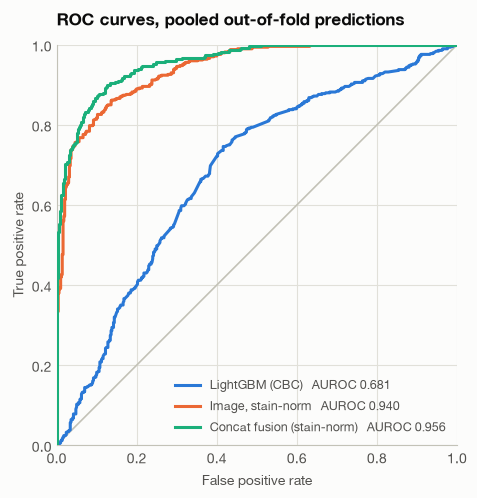

In [5]:
from sklearn.metrics import roc_curve

ROC_ARMS = [
    ("lgbm", "LightGBM (CBC)", "blue"),
    ("image_stainnorm", "Image, stain-norm", "orange"),
    ("concat_stainnorm", "Concat fusion (stain-norm)", "aqua"),
]


def draw_roc(t):
    fig, ax = viz.new_axes(t, (5.6, 5.2), grid="both", hide_left=False)
    ax.plot([0, 1], [0, 1], color=t["axis"], linewidth=1.2, zorder=1)
    for key, label, color in ROC_ARMS:
        d = preds[key]
        fpr, tpr, _ = roc_curve(d["y"], d["pred"])
        ax.plot(fpr, tpr, color=t[color], linewidth=2.2, zorder=3,
                label=f"{label}   AUROC {roc_auc_score(d['y'], d['pred']):.3f}")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.0)
    ax.set_aspect("equal")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    viz.title(ax, t, "ROC curves, pooled out-of-fold predictions")
    ax.legend(loc="lower right", frameon=False, fontsize=9, labelcolor=t["ink2"])
    return fig


viz.show_and_save(draw_roc, "roc-curves", FIG_DIR)

## 4. Paired bootstrap on the differences

Two arms scored on the same samples have correlated errors, so comparing their AUROCs side by side cannot tell you whether one truly beat the other. We bootstrap the **difference** instead:

- Resample patient **groups** with replacement, not rows.
- Score both arms on the identical resample, which is what makes it paired.
- Repeat 2000 times and take the 2.5th and 97.5th percentiles as the 95% interval.

If the interval excludes zero the difference is significant. The `confounded` flag marks comparisons between an image arm and a CBC arm: those gaps are mostly acquisition artifact and must not be quoted as a morphology-versus-CBC result.

In [6]:
COMPARISONS = [
    # challenger, incumbent, label, confounded
    ("concat_stainnorm", "image_stainnorm", "Concat fusion - image", False),
    ("film_stainnorm", "image_stainnorm", "FiLM fusion - image", False),
    ("film_stainnorm", "concat_stainnorm", "FiLM - concat fusion", False),
    ("concat_stainnorm", "lgbm", "Concat fusion - LightGBM", True),
    ("image_stainnorm", "lgbm", "Image - LightGBM", True),
    ("image_stainnorm", "image", "Stain-norm - raw image", False),
    ("lgbm", "mlp", "LightGBM - MLP", False),
    ("lgbm_withhb", "lgbm", "LightGBM + HGB/HCT - LightGBM", False),
]

rows = []
for a, b, label, confounded in COMPARISONS:
    m = preds[a].merge(preds[b], on=["sample_id", "group", "y"], suffixes=("_a", "_b"))
    assert len(m) == len(preds[a]), "prediction files do not align"
    r = bootstrap_delta(m["y"].to_numpy(), m["pred_a"].to_numpy(), m["pred_b"].to_numpy(), m["group"].to_numpy())
    rows.append({"comparison": label, "delta": r["delta"], "ci_low": r["ci_low"], "ci_high": r["ci_high"],
                 "significant": r["significant"], "confounded": confounded})
deltas = pd.DataFrame(rows)
deltas

,comparison,delta,ci_low,ci_high,significant,confounded
0,Concat fusion - image,1.591e-02,6.126e-03,0.027,True,False
1,FiLM fusion - image,1.133e-02,1.691e-04,0.023,True,False
2,FiLM - concat fusion,-4.576e-03,-1.211e-02,0.003,False,False
3,Concat fusion - LightGBM,2.750e-01,2.402e-01,0.309,True,True
4,Image - LightGBM,2.591e-01,2.214e-01,0.296,True,True
5,Stain-norm - raw image,3.324e-03,-7.752e-03,0.015,False,False
6,LightGBM - MLP,-5.828e-03,-2.557e-02,0.013,False,False
7,LightGBM + HGB/HCT - LightGBM,-3.400e-05,-2.086e-02,0.020,False,False


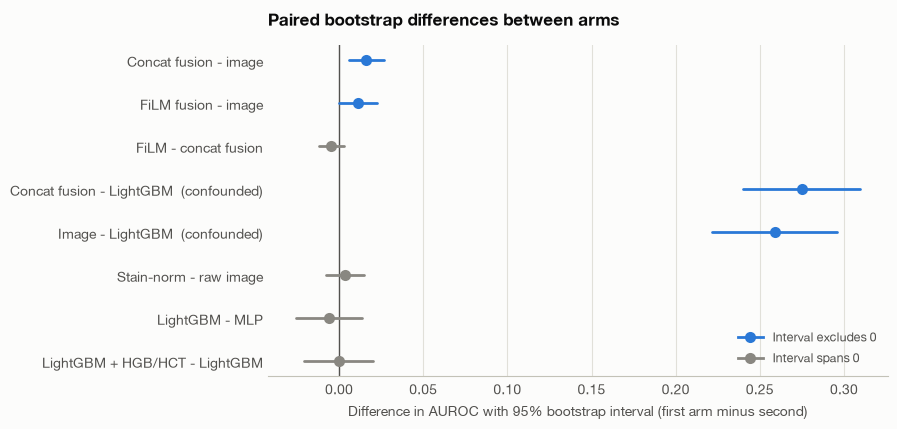

In [7]:
def draw_deltas(t):
    fig, ax = viz.new_axes(t, (8, 4.3), grid="x")
    d = deltas.iloc[::-1].reset_index(drop=True)  # first comparison on top
    for i, r in d.iterrows():
        c = t["blue"] if r["significant"] else t["muted"]
        ax.plot([r["ci_low"], r["ci_high"]], [i, i], color=c, linewidth=2, solid_capstyle="round", zorder=2)
        ax.plot(r["delta"], i, "o", color=c, markersize=8, markeredgewidth=0, zorder=3)
    ax.axvline(0, color=t["ink2"], linewidth=1.0, zorder=1)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels([c + ("  (confounded)" if f else "") for c, f in zip(d["comparison"], d["confounded"])])
    ax.set_xlabel("Difference in AUROC with 95% bootstrap interval (first arm minus second)")
    viz.title(ax, t, "Paired bootstrap differences between arms")
    viz.legend(
        ax, t,
        [
            viz.dot(t["blue"], "Interval excludes 0", line=True),
            viz.dot(t["muted"], "Interval spans 0", line=True),
        ],
        loc="lower right",
    )
    return fig


viz.show_and_save(draw_deltas, "paired-deltas", FIG_DIR)

## How to read the comparison

- **`image - LightGBM` and `concat - LightGBM` are large and tightly bounded, but confounded.** They are the cautionary example: a publishable-looking effect that largely measures which imaging session a slide came from.
- **`concat - image` is the one defensible image-involving number.** Both arms carry the same artifact, so the difference largely cancels it and isolates what the CBC adds on top of the image. It is small and positive, with an interval that excludes zero.
- **FiLM matches concat fusion** (interval spans zero), so the extra conditioning machinery buys nothing here.
- **LightGBM and the MLP are indistinguishable.** That matters: a fusion gain cannot be dismissed as a crippled tabular branch.
- **Adding HGB and HCT changes nothing** (difference of about zero), which settles the question of whether excluding them mattered.

To compare your own arm, write its out-of-fold predictions to `artifacts/preds/<name>.csv` (columns `sample_id, group, y, fold, pred`) or run `python -m src.train --compare <challenger> <incumbent>`.